# 🩺 Prenatal Anemia Screening – Full Training Pipeline

**Run this on Google Colab with GPU enabled.**

Go to: `Runtime → Change runtime type → GPU (T4)`

This notebook will:
1. Clone your GitHub repo
2. Install dependencies
3. Train all 3 models (Image, Tabular, Fusion)
4. Save comprehensive results for the research paper
5. Zip everything for download

## 📦 Step 1 – Setup & Clone Repo

In [13]:
# Check GPU
!nvidia-smi
import torch
print(f"\n✅ CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"   GPU: {torch.cuda.get_device_name(0)}")

Tue Oct 13 16:04:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [14]:
# Clone the repo
!rm -rf PrenatalAnemia
!git clone https://github.com/Manideep1617-wq/Prenatal-Anemia.git PrenatalAnemia
%cd PrenatalAnemia
!ls -la

Cloning into 'PrenatalAnemia'...
remote: Enumerating objects: 70, done.
remote: Counting objects: 100% (3/3), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 70 (delta 0), reused 2 (delta 0), pack-reused 67 (from 1)
Receiving objects: 100% (70/70), 80.19 MiB | 30.63 MiB/s, done.
Resolving deltas: 100% (12/12), done.
/content/PrenatalAnemia
total 100
drwxr-xr-x 7 root root  4096 Oct 13 16:04 .
drwxr-xr-x 1 root root  4096 Oct 13 16:04 ..
-rw-r--r-- 1 root root 19563 Oct 13 16:04 app.py
-rw-r--r-- 1 root root   924 Oct 13 16:04 extract_pdfs.py
-rw-r--r-- 1 root root  6155 Oct 13 16:04 Feature_Roadmap.md
drwxr-xr-x 8 root root  4096 Oct 13 16:04 .git
-rw-r--r-- 1 root root   536 Oct 13 16:04 .gitignore
drwxr-xr-x 3 root root  4096 Oct 13 16:04 paper
-rw-r--r-- 1 root root  6467 Oct 13 16:04 paper_comparison_table.md
-rw-r--r-- 1 root root 12811 Oct 13 16:04 PrenatalAnemia_Training.ipynb
-rw-r--r-- 1 root root   188 Oct 13 16:04 requirements.txt
drwxr-xr-x 4 root root  4

In [15]:
# Install dependencies
!pip install -q xgboost>=2.0.0 shap opencv-python-headless altair fpdf torchcam seaborn

## 📂 Step 2 – Upload Your Data

You need to upload your `data/` folder. **Two options:**

**Option A – Upload a zip file** (recommended):
1. Zip your entire `data/` folder on your PC
2. Run the cell below and upload the zip

**Option B – Mount Google Drive:**
1. Upload the data folder to your Google Drive
2. Uncomment the Drive mount cell below

In [16]:
# OPTION A: Upload data.zip
# This will open a file picker — upload your data.zip file

import os
from google.colab import files

print("📁 Upload your data.zip file (containing cbc_dataframe.csv, Dataset - Updated.csv, Dataset_sample/ folder)")
uploaded = files.upload()

# Extract
!mkdir -p data
for fname in uploaded.keys():
    if fname.endswith('.zip'):
        !unzip -o "{fname}" -d data/
        print(f"✅ Extracted {fname}")

# Check what's inside
!echo "\n📂 Contents of data/:"
!find data/ -maxdepth 2 -type f | head -20
!echo "\n📂 Image folders:"
!ls data/Dataset_sample/ 2>/dev/null || echo "⚠️ Dataset_sample not found — check zip structure"

📁 Upload your data.zip file (containing cbc_dataframe.csv, Dataset - Updated.csv, Dataset_sample/ folder)


Streaming output truncated to the last 5000 lines.
  inflating: data/Dataset_sample/Nail_Anemic/Anemic-014 (6).png  
  inflating: data/Dataset_sample/Nail_Anemic/Anemic-014 (7) 2.png  
  inflating: data/Dataset_sample/Nail_Anemic/Anemic-014 (7).png  
  inflating: data/Dataset_sample/Nail_Anemic/Anemic-014 (8) 2.png  
  inflating: data/Dataset_sample/Nail_Anemic/Anemic-014 (8).png  
  inflating: data/Dataset_sample/Nail_Anemic/Anemic-014 (9) 2.png  
  inflating: data/Dataset_sample/Nail_Anemic/Anemic-014 (9).png  
  inflating: data/Dataset_sample/Nail_Anemic/Anemic-014 2.png  
  inflating: data/Dataset_sample/Nail_Anemic/Anemic-014.png  
  inflating: data/Dataset_sample/Nail_Anemic/Anemic-015 (10) 2.png  
  inflating: data/Dataset_sample/Nail_Anemic/Anemic-015 (10).png  
  inflating: data/Dataset_sample/Nail_Anemic/Anemic-015 (11) 2.png  
  inflating: data/Dataset_sample/Nail_Anemic/Anemic-015 (11).png  
  inflating: data/Dataset_sample/Nail_Anemic/Anemic-015 (12) 2.png  
  inflating: d

In [17]:
# # OPTION B: Mount Google Drive (uncomment if using Drive instead of upload)
# from google.colab import drive
# drive.mount('/content/drive')
# !cp -r /content/drive/MyDrive/PrenatalAnemia/data ./data
# !ls data/

## ⚙️ Step 3 – Fix Config Paths for Colab

In [18]:
# Update config.yaml to use Colab paths
import yaml

colab_config = {
    'paths': {
        'data_dir': '/content/PrenatalAnemia/data',
        'image_dir': '/content/PrenatalAnemia/data/Dataset_sample',
        'results_dir': '/content/PrenatalAnemia/results',
    },
    'training': {
        'seed': 42,
        'batch_size': 32,
        'image_epochs': 10,
        'lr': 0.0001,
    }
}

with open('src/config.yaml', 'w') as f:
    yaml.dump(colab_config, f, default_flow_style=False)

print("✅ Config updated for Colab:")
!cat src/config.yaml

✅ Config updated for Colab:
paths:
  data_dir: /content/PrenatalAnemia/data
  image_dir: /content/PrenatalAnemia/data/Dataset_sample
  results_dir: /content/PrenatalAnemia/results
training:
  batch_size: 32
  image_epochs: 10
  lr: 0.0001
  seed: 42


## 🔍 Step 4 – Verify Data Is Ready

In [19]:
import pandas as pd
import os

# Check tabular data
cbc_path = '/content/PrenatalAnemia/data/cbc_dataframe.csv'
mat_path = '/content/PrenatalAnemia/data/Dataset - Updated.csv'
img_dir  = '/content/PrenatalAnemia/data/Dataset_sample'

print("=" * 50)
if os.path.exists(cbc_path):
    cbc = pd.read_csv(cbc_path)
    print(f"✅ CBC data: {len(cbc):,} rows, {len(cbc.columns)} columns")
else:
    print("❌ CBC data NOT found")

if os.path.exists(mat_path):
    mat = pd.read_csv(mat_path)
    print(f"✅ Maternal data: {len(mat):,} rows, {len(mat.columns)} columns")
else:
    print("❌ Maternal data NOT found")

if os.path.isdir(img_dir):
    for folder in ['Eye_Anemic', 'Eye_Non_Anemic', 'Nail_Anemic', 'Nail_Non_Anemic']:
        fp = os.path.join(img_dir, folder)
        if os.path.isdir(fp):
            count = len([f for f in os.listdir(fp) if f.lower().endswith(('.jpg','.jpeg','.png','.bmp'))])
            print(f"   📁 {folder}: {count} images")
else:
    print("❌ Image folder NOT found")
print("=" * 50)

✅ CBC data: 115,487 rows, 20 columns
✅ Maternal data: 1,205 rows, 12 columns
   📁 Eye_Anemic: 1786 images
   📁 Eye_Non_Anemic: 1782 images
   📁 Nail_Anemic: 1718 images
   📁 Nail_Non_Anemic: 1755 images


## 🚀 Step 5 – Run Full Training Pipeline

This trains all 3 models and saves everything:
- Phase 1: Image Model (ResNet-18)
- Phase 2: Tabular Model (XGBoost)
- Phase 3: Transformer Fusion Model

In [20]:
import os

# Safely change directory if not already there
target_dir = '/content/PrenatalAnemia'
if os.path.exists(target_dir):
    os.chdir(target_dir)
    print(f"✅ Working directory set to: {os.getcwd()}")
else:
    print(f"⚠️ {target_dir} not found. Current directory: {os.getcwd()}")

!python -m src.train

✅ Working directory set to: /content/PrenatalAnemia
Device: cuda
Config: epochs=10, batch_size=32, lr=0.0001

Loading tabular datasets …
Loading CBC dataset …
  CBC: 103,221 rows | anemic=2,551  non-anemic=100,670
Loading Maternal Health CSV …
  Maternal: 1,179 rows | high-risk=465
Tabular split → train=83,520  val=20,880  features=17
Features: ['Age', 'BMI', 'BS', 'Body Temp', 'Diastolic', 'HCT', 'HGB', 'Heart Rate', 'MCH', 'MCHC', 'MCV', 'MPV', 'PLT', 'RBC', 'RDW', 'Systolic BP', 'WBC']
[██░░░░░░░░░░░░░░░░░░] 10%  Tabular data loaded

Loading image datasets …
Image train set: 5,632 images | anemic=2,843  non-anemic=2,789
Image val set: 1,409 images | anemic=661  non-anemic=748
[████░░░░░░░░░░░░░░░░] 20%  Image data loaded
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 197MB/s]
  ImageModel: ResNet-18 (pretrained=True)  embed_dim=512

  PHASE 1 – Training Image Model (R

## 📊 Step 6 – View Results

In [21]:
# Display the consolidated metrics
import json

with open('results/metrics.json', 'r') as f:
    metrics = json.load(f)

print("=" * 60)
print("  📊 TRAINING RESULTS SUMMARY")
print("=" * 60)
summary = metrics['summary']
print(f"  Image Model   → Acc: {summary['image_accuracy']:.4f}  F1: {summary['image_f1']:.4f}  AUC: {summary['image_auc']}")
print(f"  Tabular Model → Acc: {summary['tabular_accuracy']:.4f}  F1: {summary['tabular_f1']:.4f}  AUC: {summary['tabular_auc']}")
print(f"  Fusion Model  → Acc: {summary['fusion_accuracy']:.4f}  F1: {summary['fusion_f1']:.4f}")
print(f"\n  Training time: {metrics['training_time_minutes']:.1f} minutes")
print(f"  Device: {metrics['device']}")
print("=" * 60)

  📊 TRAINING RESULTS SUMMARY
  Image Model   → Acc: 0.9482  F1: 0.9482  AUC: 0.988568608573948
  Tabular Model → Acc: 0.9994  F1: 0.9994  AUC: 0.9999411140774894
  Fusion Model  → Acc: 0.9390  F1: 0.9390

  Training time: 14.8 minutes
  Device: cuda


📈 14 figures generated:

--- fusion_accuracy_curves.png ---


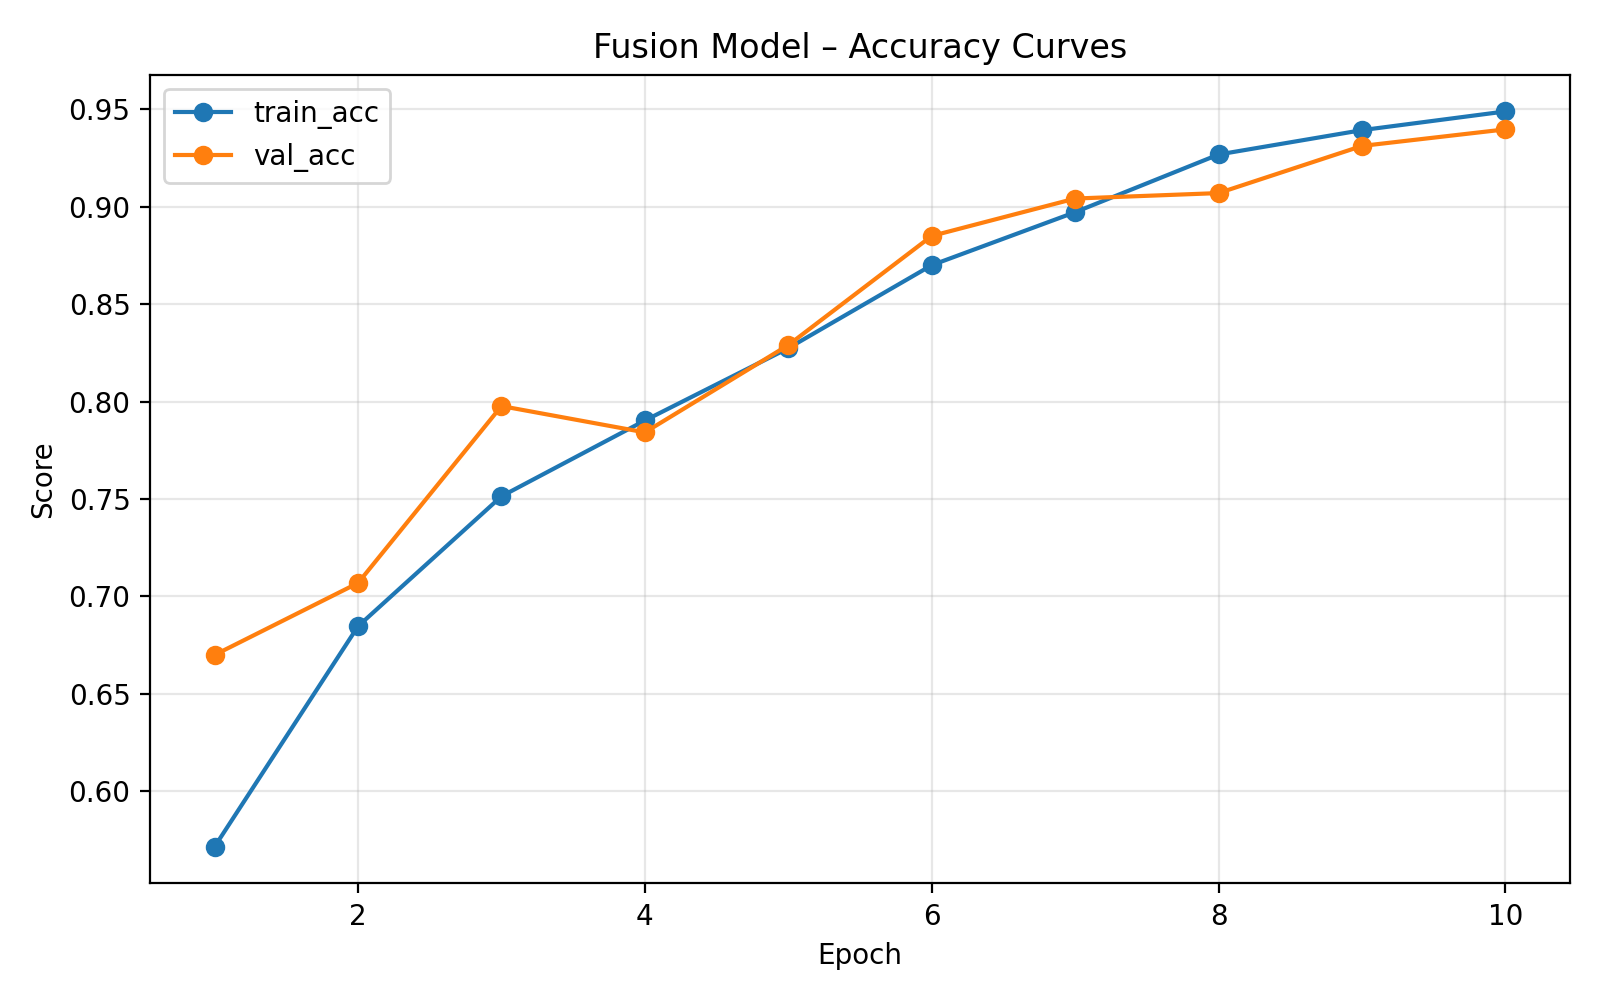


--- fusion_confusion_matrix.png ---


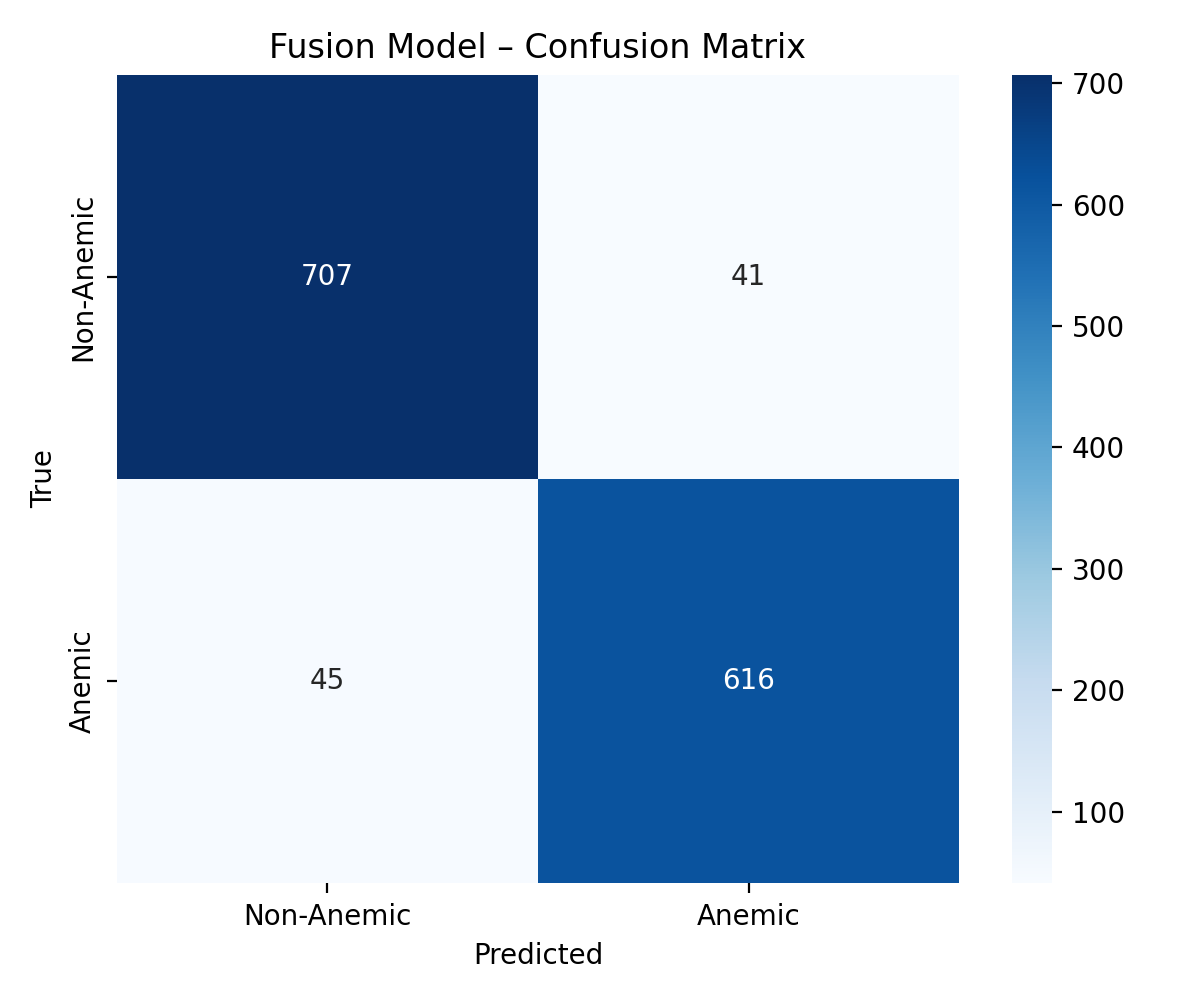


--- fusion_loss_curves.png ---


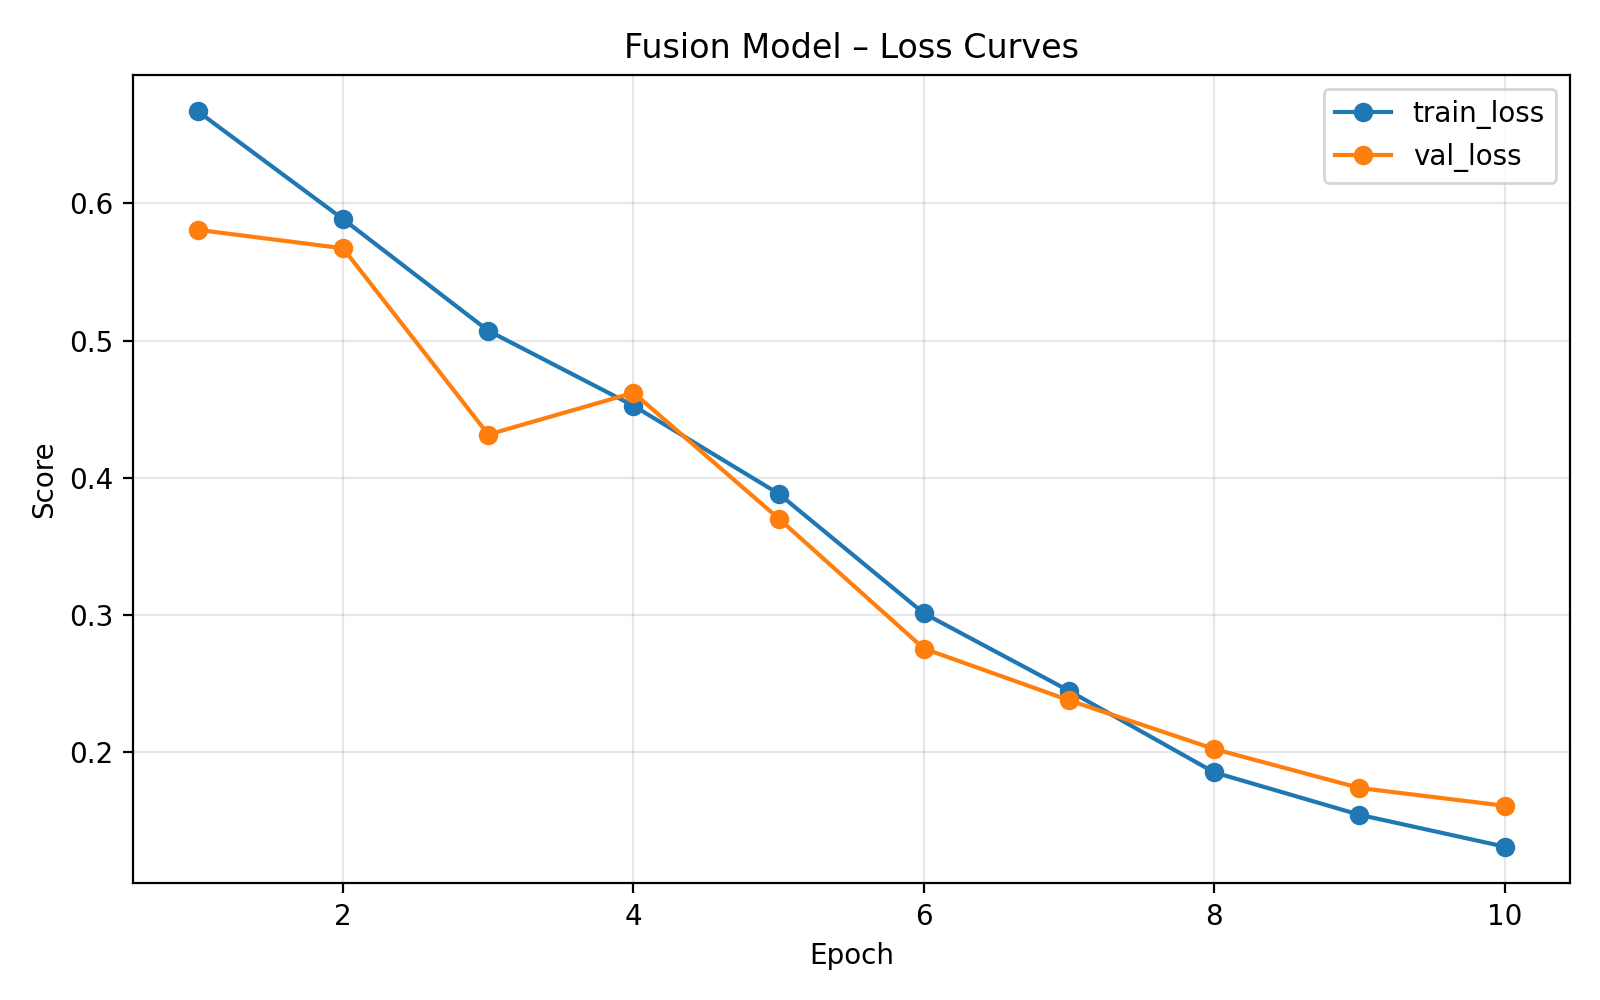


--- image_accuracy_curves.png ---


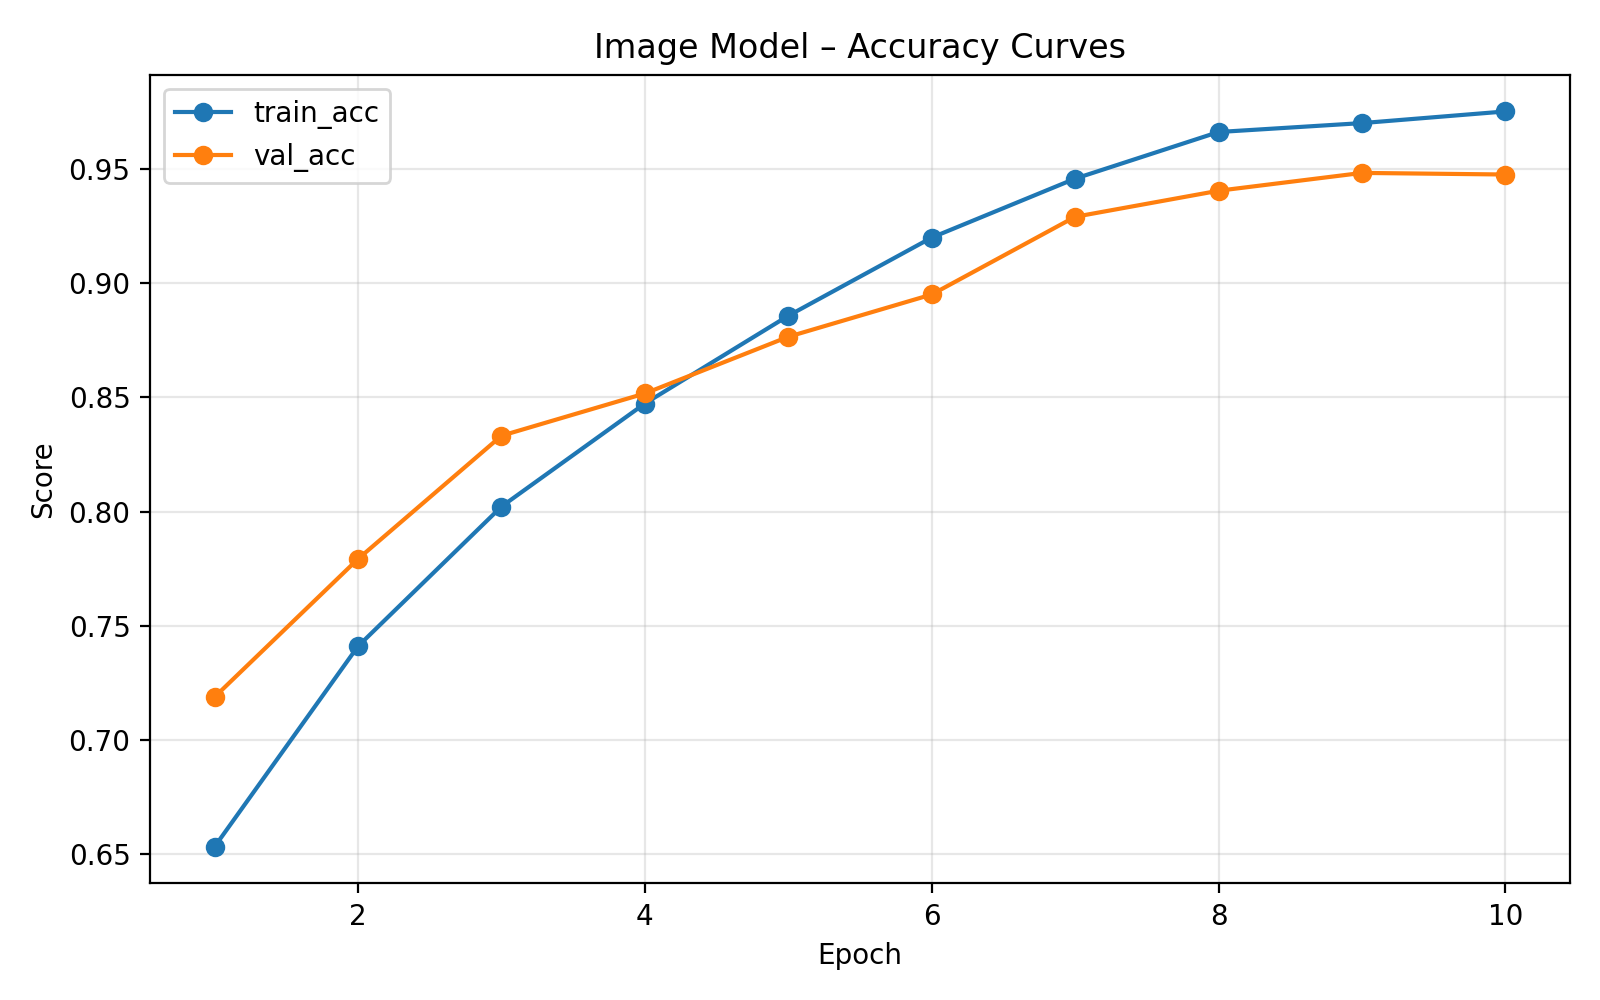


--- image_confusion_matrix.png ---


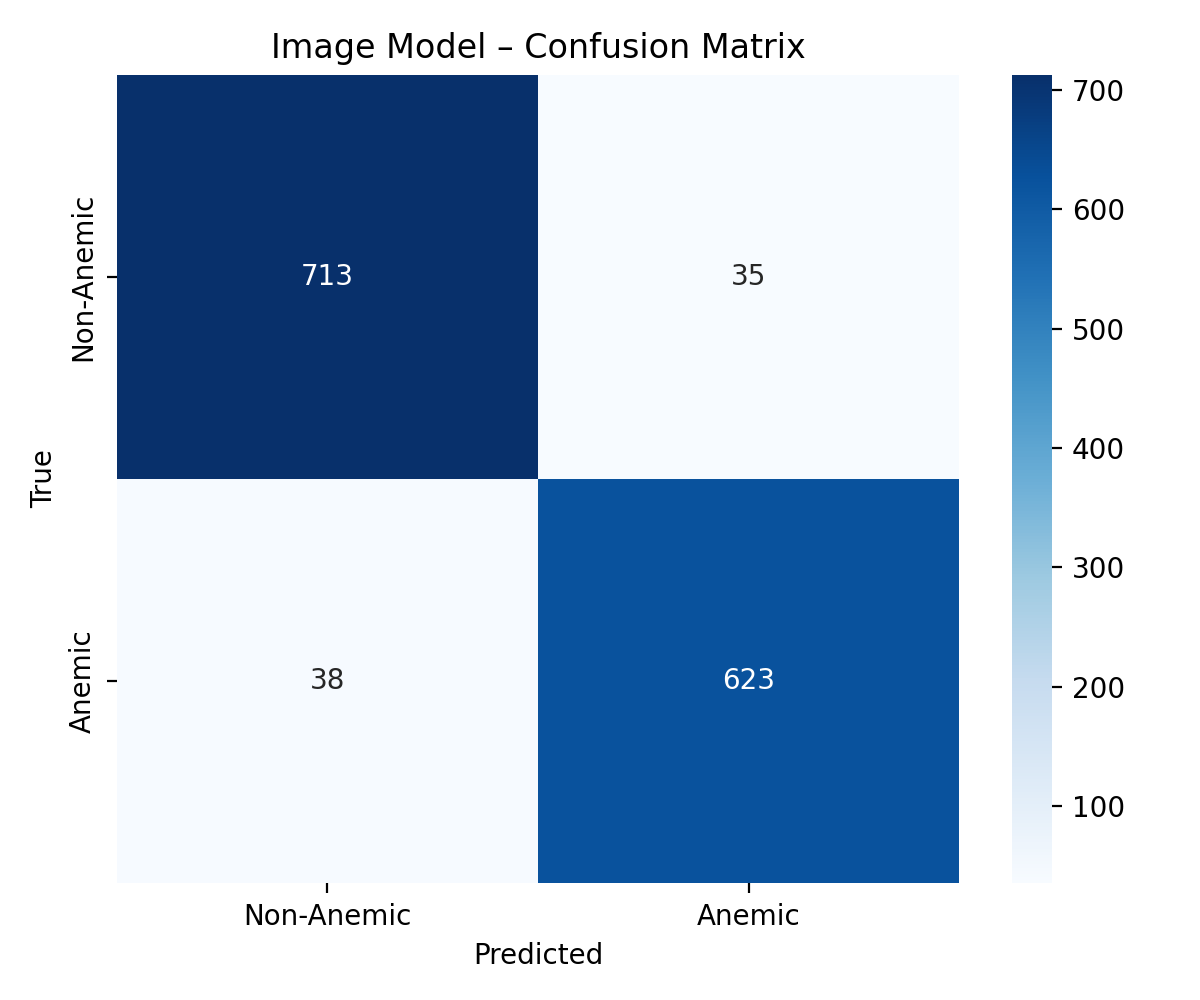


--- image_loss_curves.png ---


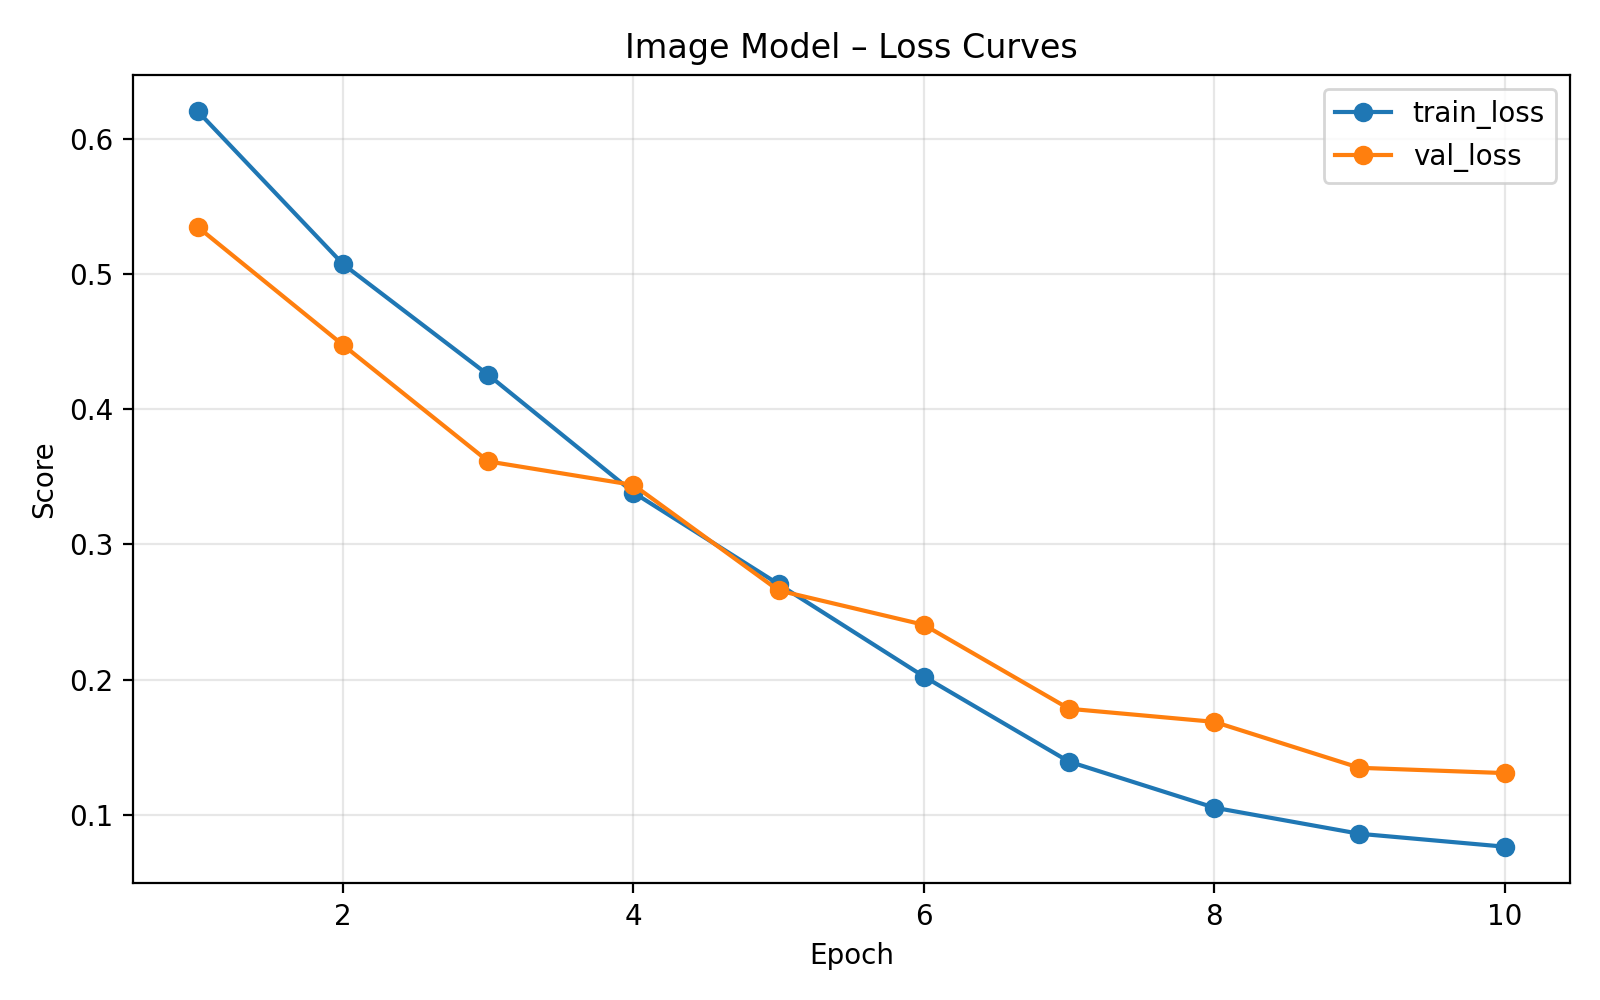


--- image_pr_curve.png ---


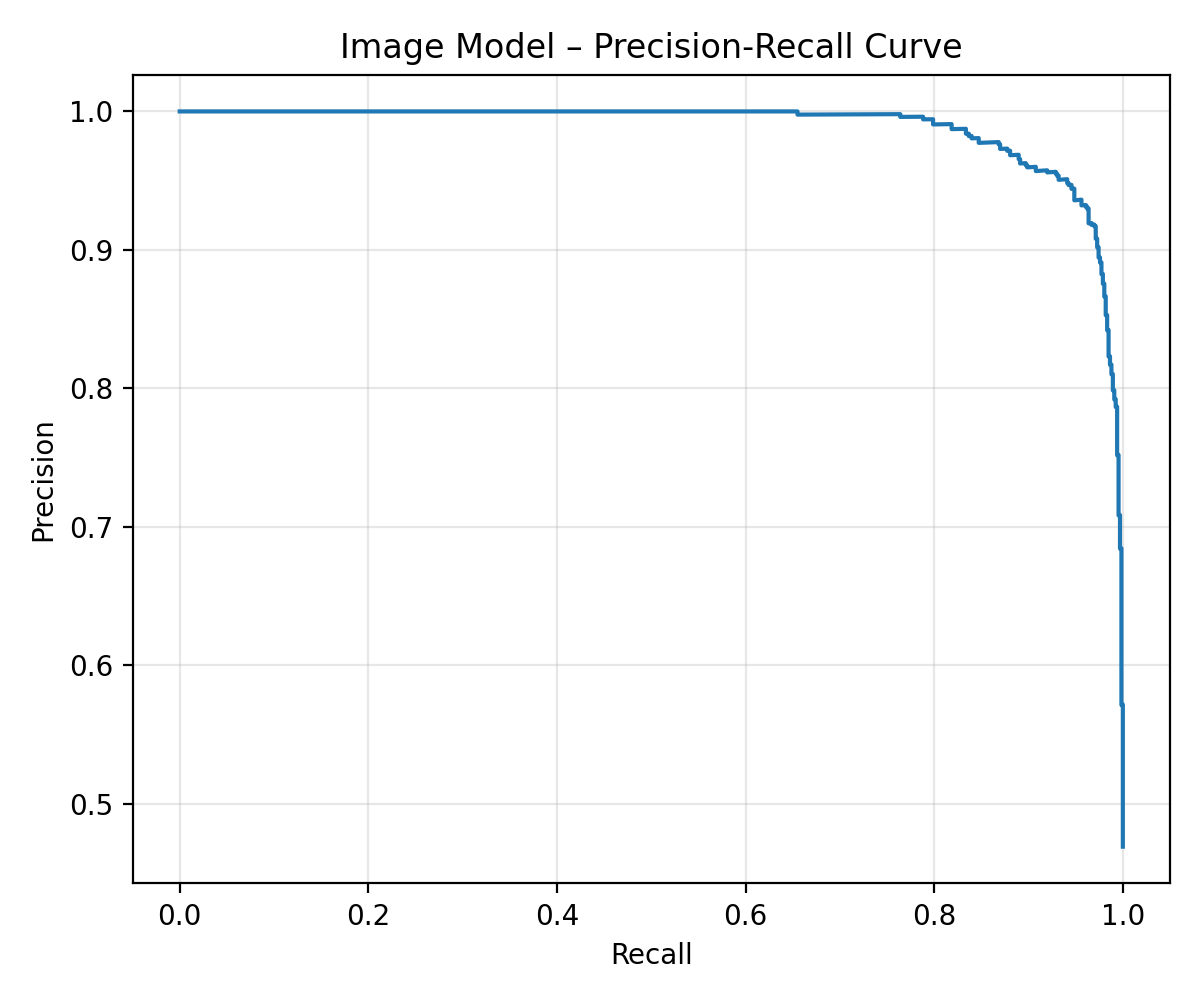


--- image_roc_curve.png ---


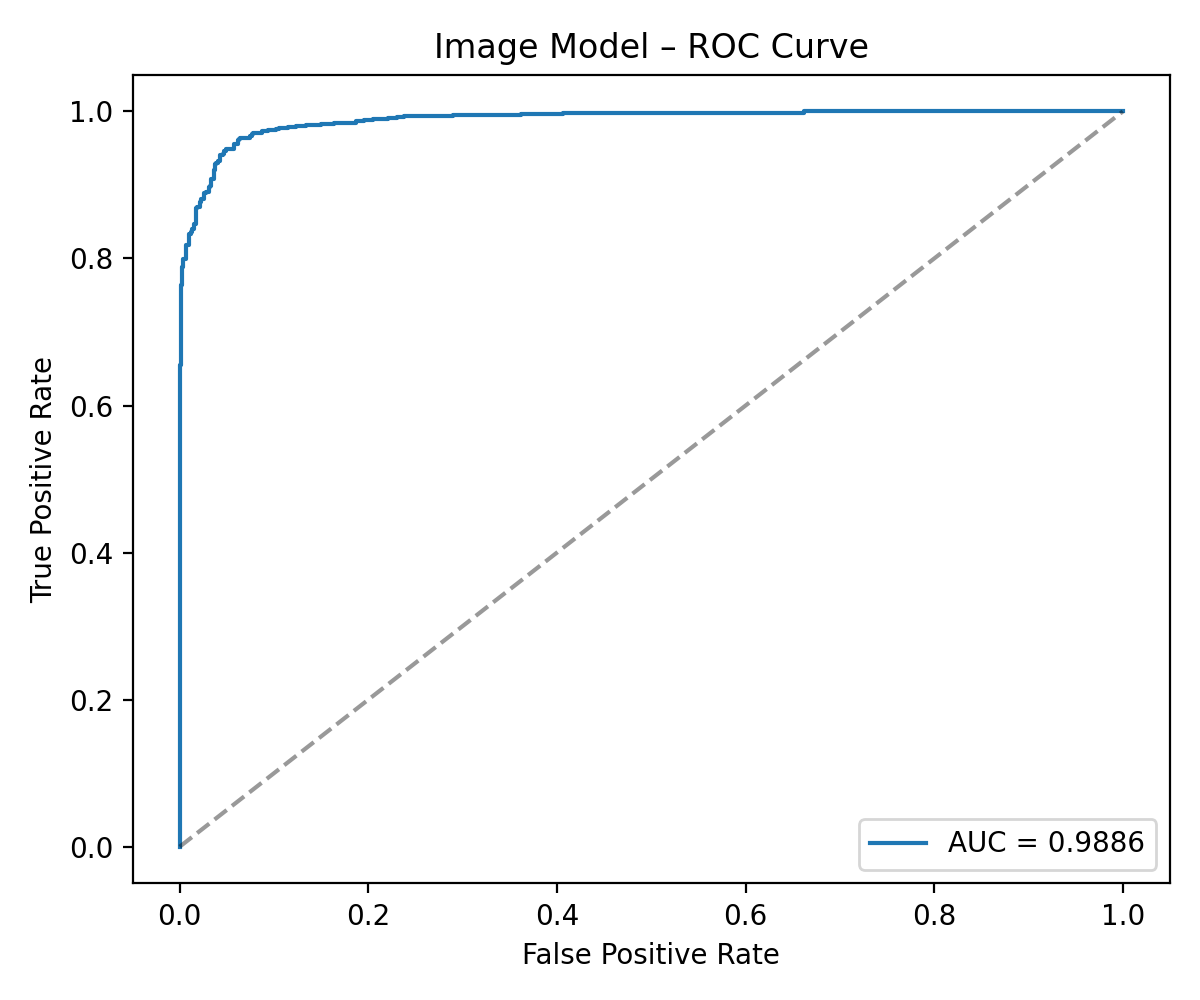


--- img_confusion_matrix.png ---


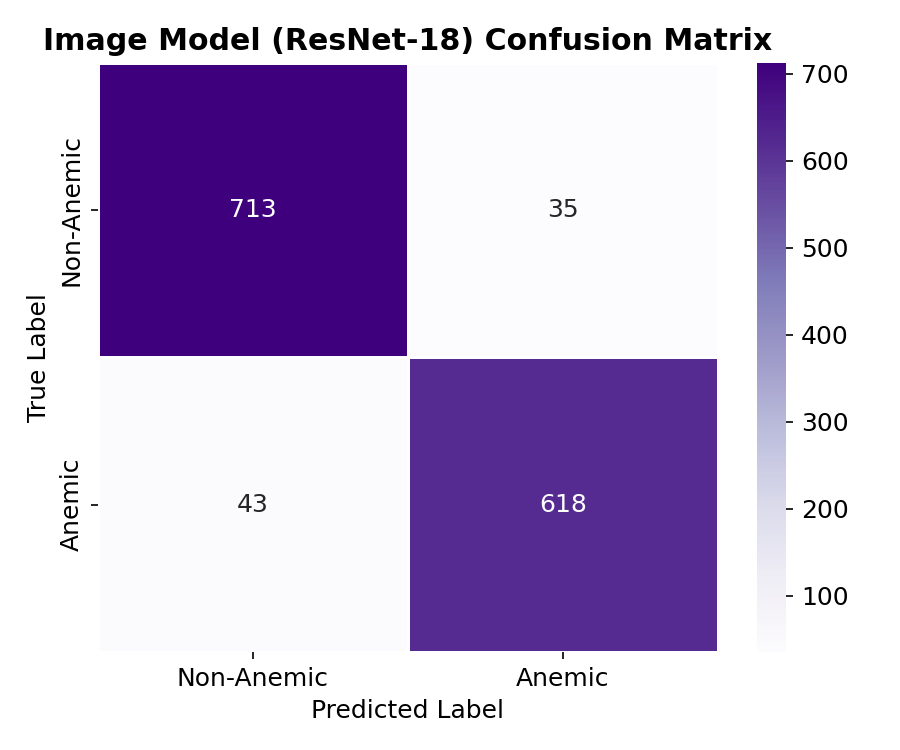


--- model_comparison.png ---


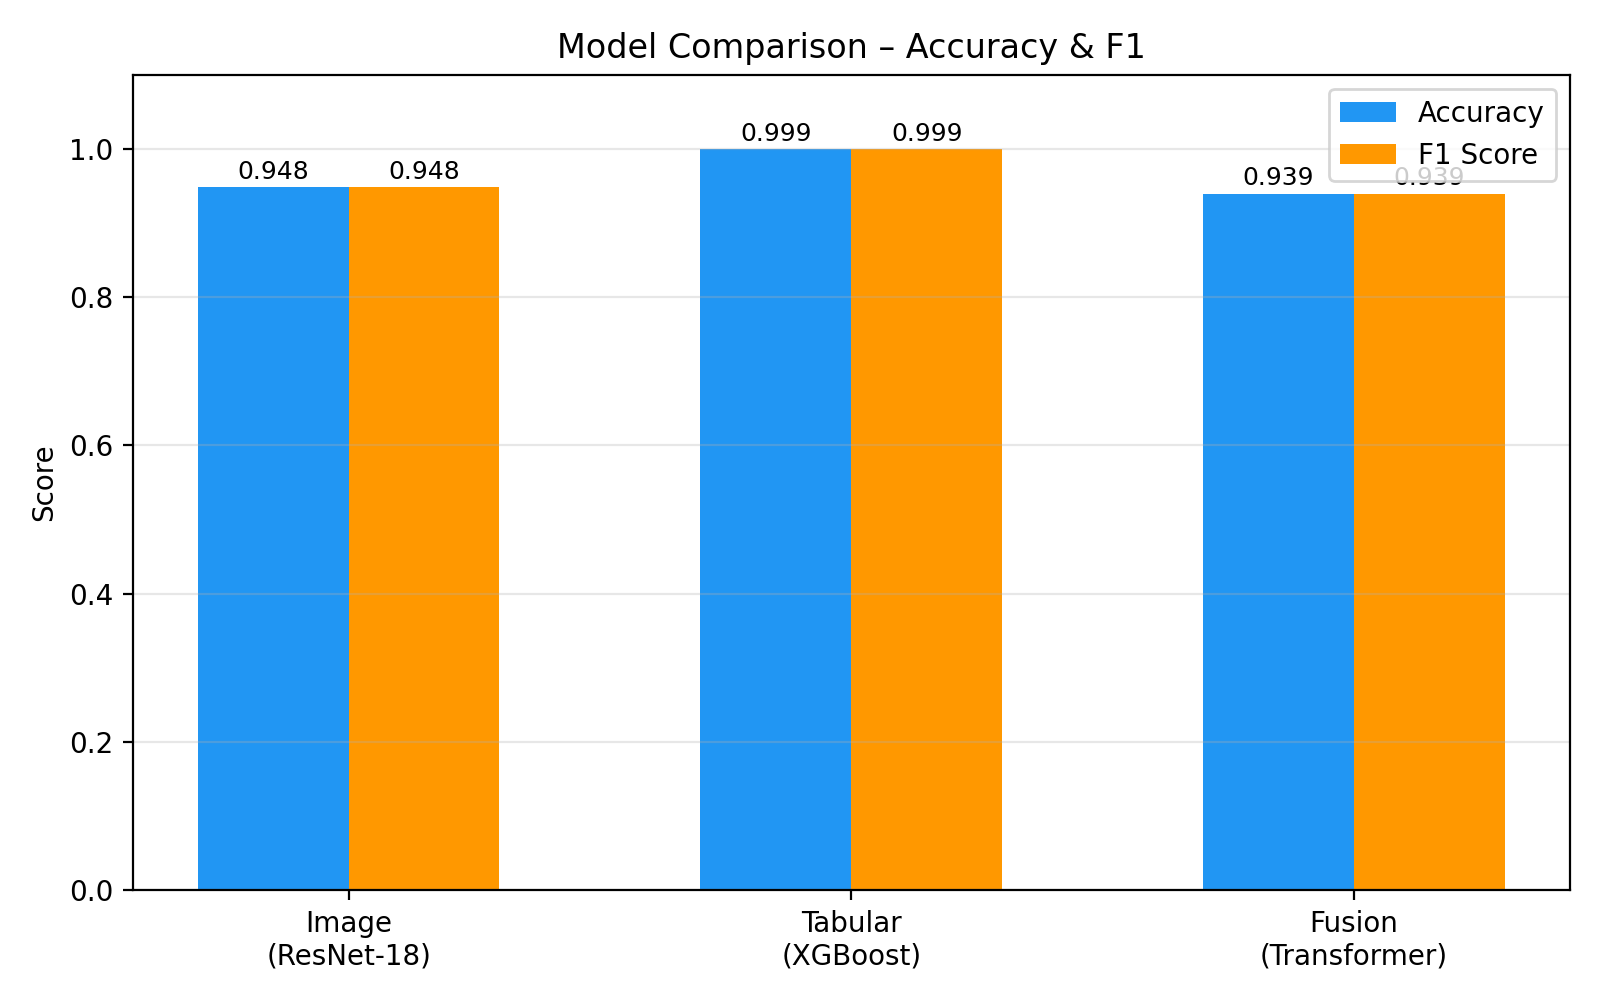


--- tabular_confusion_matrix.png ---


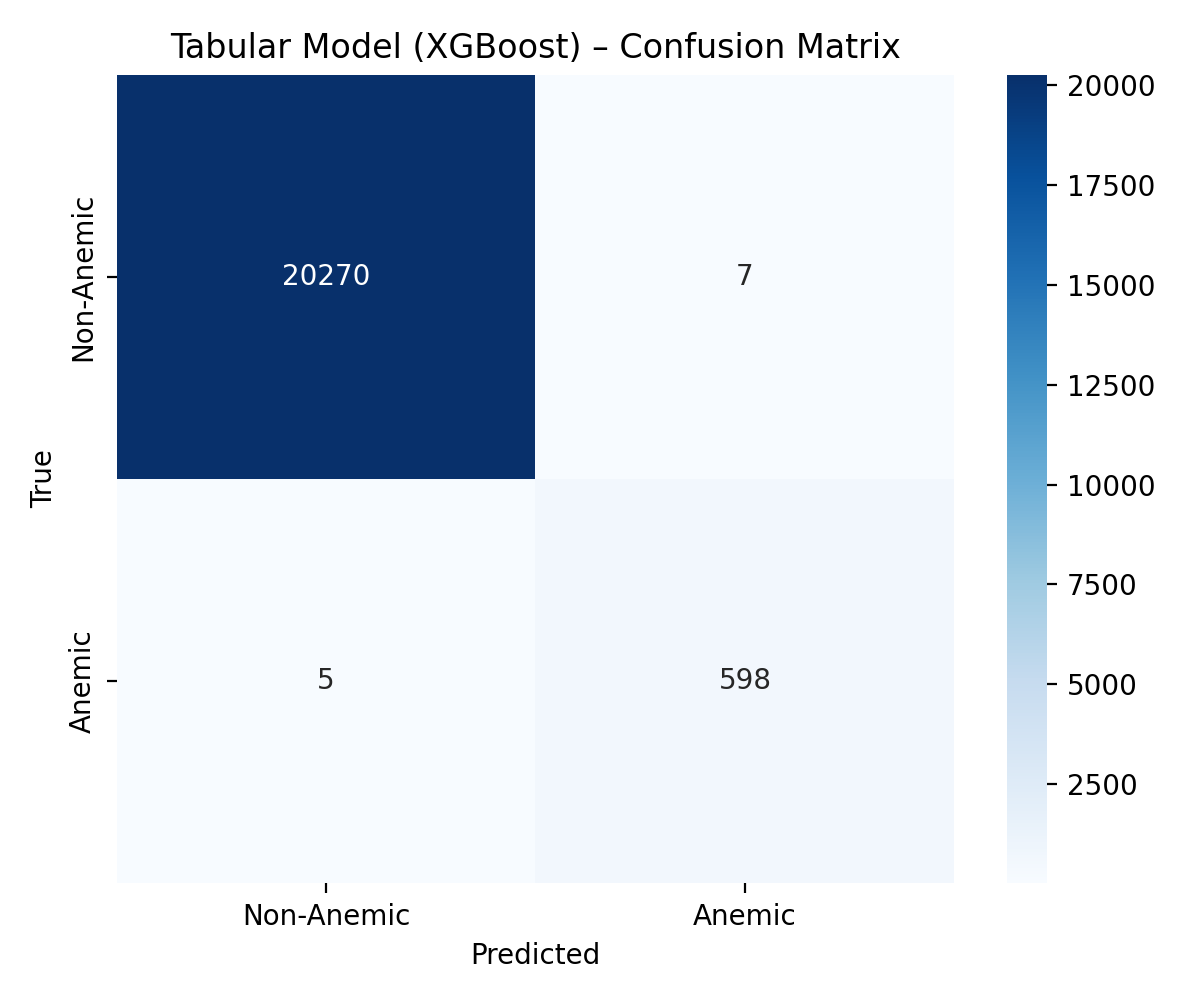


--- tabular_feature_importance.png ---


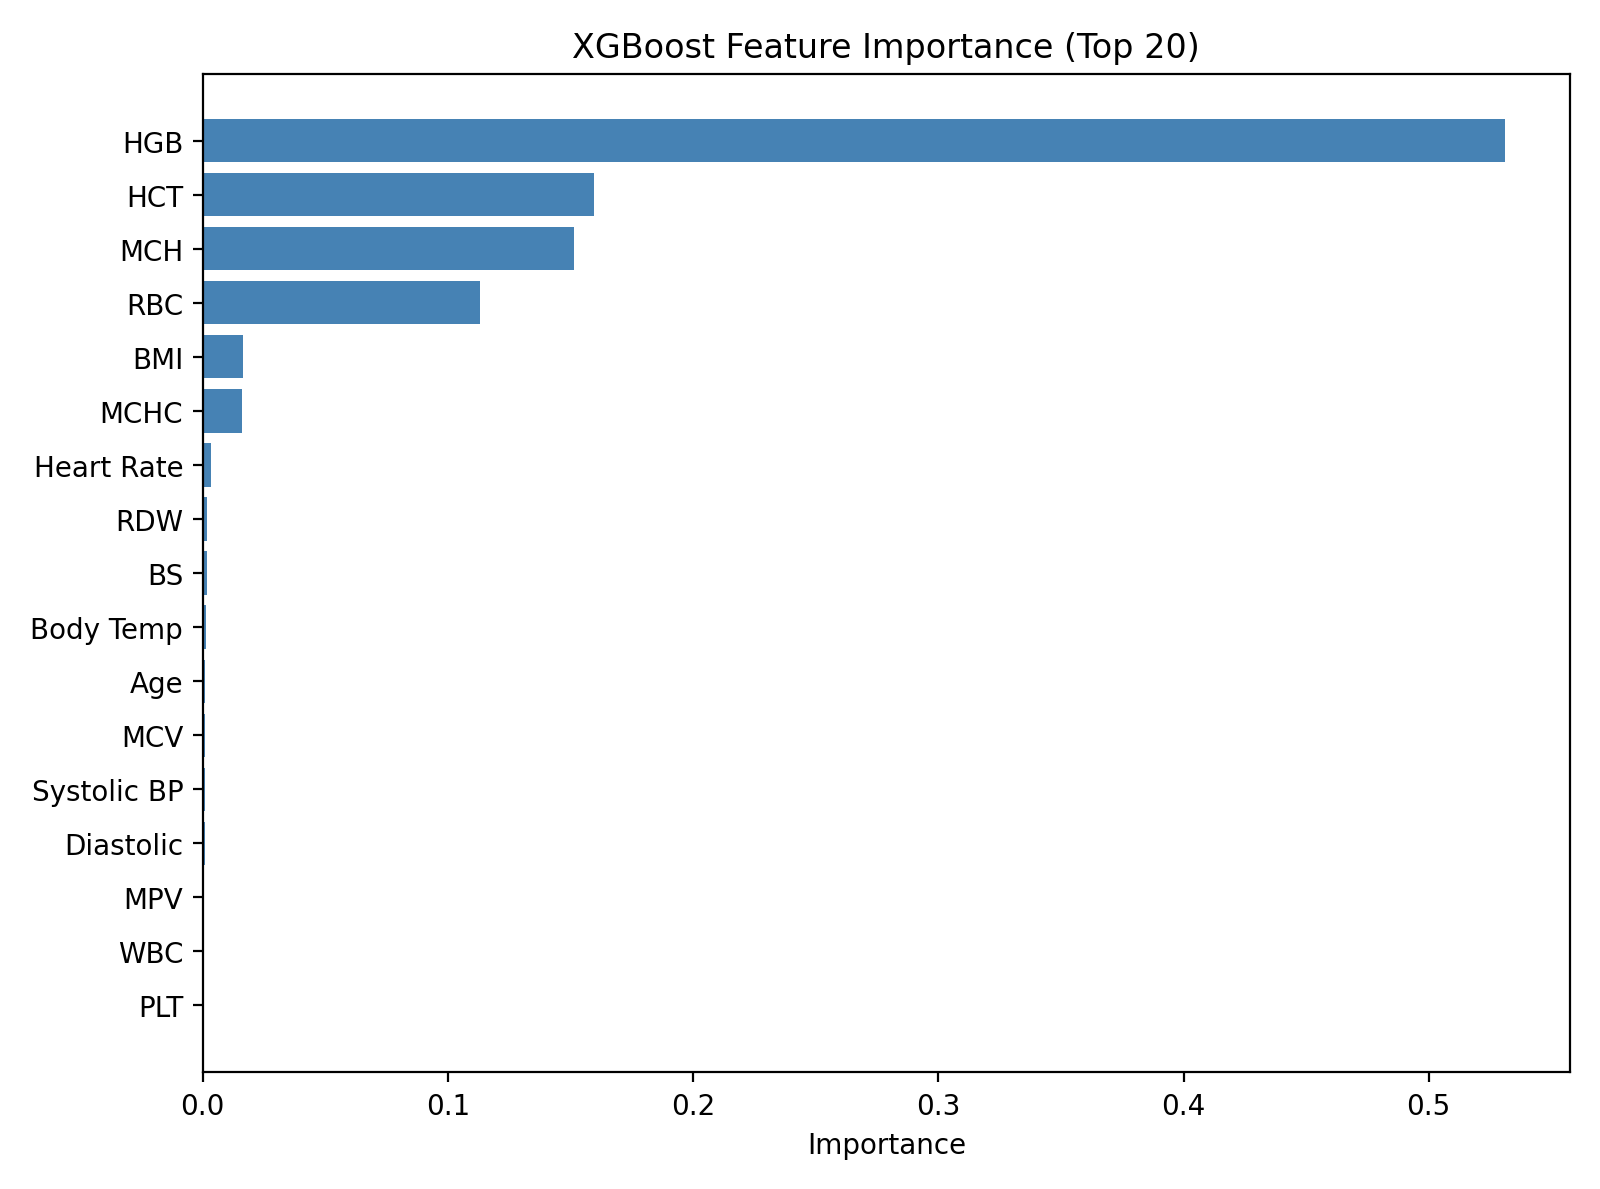


--- tabular_pr_curve.png ---


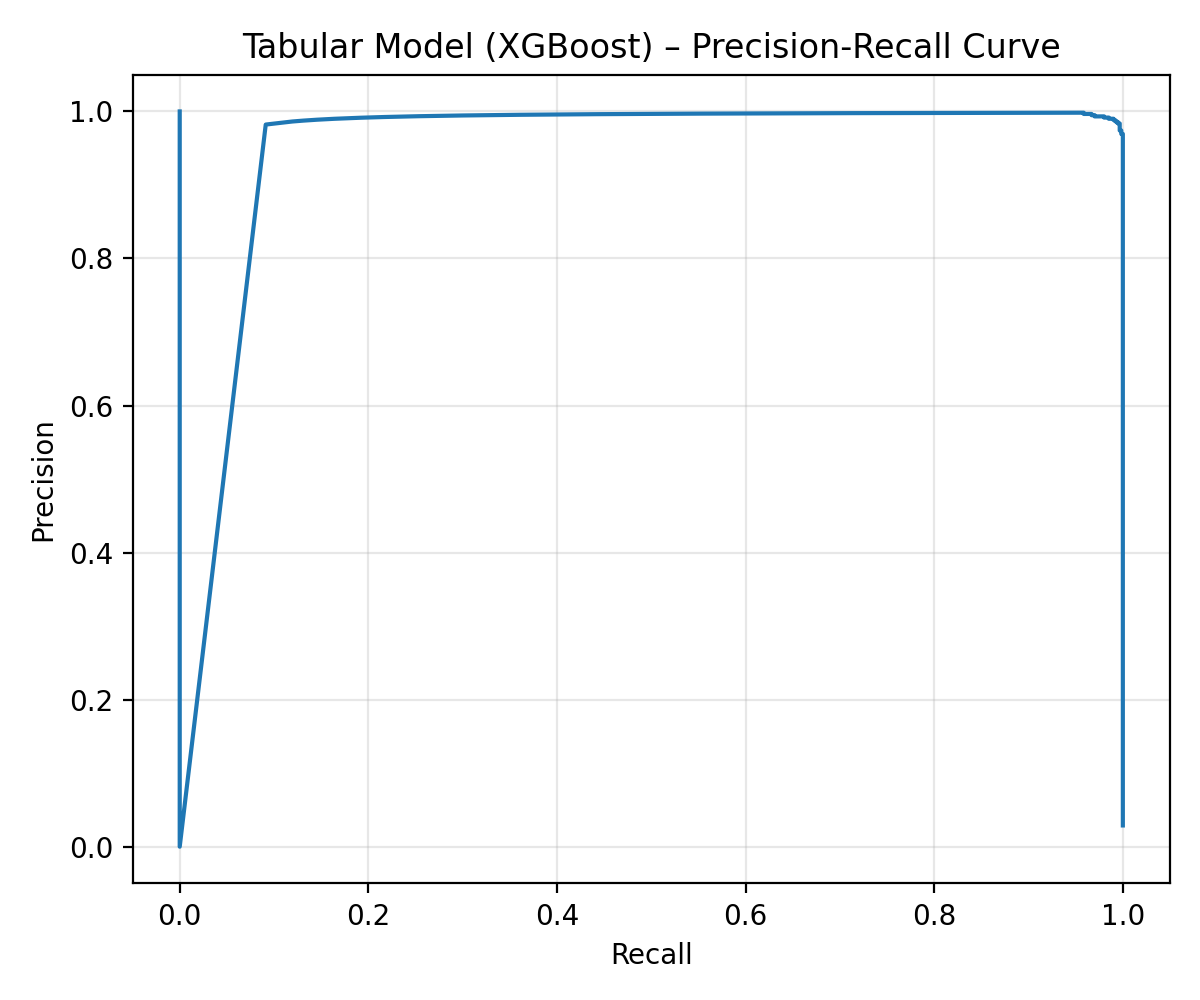


--- tabular_roc_curve.png ---


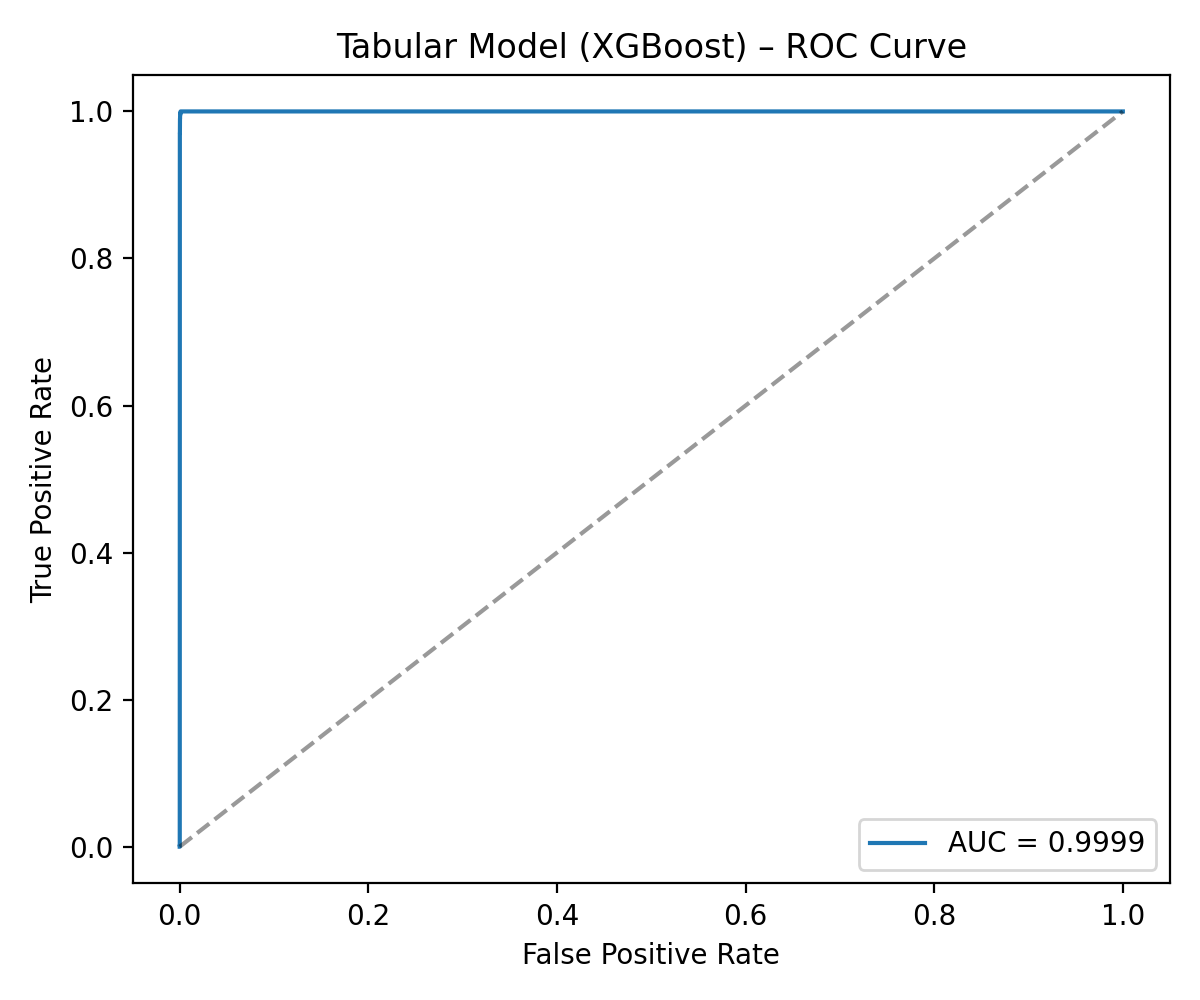

In [22]:
# Display all generated figures
from IPython.display import display, Image as IPImage
import glob

fig_files = sorted(glob.glob('results/figures/*.png'))
print(f"📈 {len(fig_files)} figures generated:\n")
for fig_path in fig_files:
    print(f"--- {os.path.basename(fig_path)} ---")
    display(IPImage(filename=fig_path, width=600))
    print()

In [23]:
# Show classification reports
for model_name in ['image', 'tabular', 'fusion']:
    report_path = f'results/records/{model_name}_classification_report.txt'
    if os.path.exists(report_path):
        print(f"\n{'='*50}")
        print(f"  {model_name.upper()} MODEL – Classification Report")
        print(f"{'='*50}")
        with open(report_path) as f:
            print(f.read())


  IMAGE MODEL – Classification Report
              precision    recall  f1-score   support

  Non-Anemic       0.95      0.95      0.95       748
      Anemic       0.95      0.94      0.94       661

    accuracy                           0.95      1409
   macro avg       0.95      0.95      0.95      1409
weighted avg       0.95      0.95      0.95      1409


  TABULAR MODEL – Classification Report
              precision    recall  f1-score   support

  Non-Anemic       1.00      1.00      1.00     20277
      Anemic       0.99      0.99      0.99       603

    accuracy                           1.00     20880
   macro avg       0.99      1.00      0.99     20880
weighted avg       1.00      1.00      1.00     20880


  FUSION MODEL – Classification Report
              precision    recall  f1-score   support

  Non-Anemic       0.94      0.95      0.94       748
      Anemic       0.94      0.93      0.93       661

    accuracy                           0.94      1409
   macro

In [24]:
# Show feature importance (tabular model)
fi_path = 'results/records/tabular_feature_importance.csv'
if os.path.exists(fi_path):
    fi = pd.read_csv(fi_path)
    print("\n🔬 XGBoost Feature Importance:")
    print(fi.to_string(index=False))


🔬 XGBoost Feature Importance:
    feature  importance
        HGB    0.531051
        HCT    0.159598
        MCH    0.151276
        RBC    0.112965
        BMI    0.016530
       MCHC    0.016009
 Heart Rate    0.003566
        RDW    0.001851
         BS    0.001784
  Body Temp    0.001157
        Age    0.001038
        MCV    0.000852
Systolic BP    0.000827
  Diastolic    0.000795
        MPV    0.000339
        WBC    0.000206
        PLT    0.000156


## 📥 Step 7 – Download All Results

This zips the entire `results/` folder for you to download and bring back.

In [25]:
# Zip all results for download
!zip -r /content/prenatal_anemia_results.zip results/

from google.colab import files
files.download('/content/prenatal_anemia_results.zip')

print("\n✅ Download started! This zip contains:")
print("   📁 results/checkpoints/   → Model weights")
print("   📁 results/records/        → Epoch logs, classification reports, confusion matrices")
print("   📁 results/figures/        → All plots (PNG) for the research paper")
print("   📄 results/metrics.json    → Consolidated metrics with hyperparams & dataset stats")

  adding: results/ (stored 0%)
  adding: results/records/ (stored 0%)
  adding: results/records/image_epoch_log.csv (deflated 59%)
  adding: results/records/image_classification_report.json (deflated 59%)
  adding: results/records/tabular_classification_report.json (deflated 60%)
  adding: results/records/fusion_epoch_log.json (deflated 81%)
  adding: results/records/tabular_classification_report.txt (deflated 59%)
  adding: results/records/image_epoch_log.json (deflated 81%)
  adding: results/records/image_confusion_matrix.csv (deflated 33%)
  adding: results/records/tabular_confusion_matrix.csv (deflated 33%)
  adding: results/records/image_classification_report.txt (deflated 62%)
  adding: results/records/fusion_classification_report.txt (deflated 61%)
  adding: results/records/fusion_confusion_matrix.csv (deflated 33%)
  adding: results/records/tabular_feature_importance.csv (deflated 33%)
  adding: results/records/fusion_classification_report.json (deflated 61%)
  adding: results/

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ Download started! This zip contains:
   📁 results/checkpoints/   → Model weights
   📁 results/records/        → Epoch logs, classification reports, confusion matrices
   📁 results/figures/        → All plots (PNG) for the research paper
   📄 results/metrics.json    → Consolidated metrics with hyperparams & dataset stats


## 🔁 Step 8 – List All Generated Files

In [26]:
# Show everything that was generated
import os

print("\n📂 Complete results directory:")
for root, dirs, fnames in os.walk('results/'):
    level = root.replace('results/', '').count(os.sep)
    indent = '  ' * level
    print(f"{indent}📁 {os.path.basename(root)}/")
    sub_indent = '  ' * (level + 1)
    for fn in sorted(fnames):
        fpath = os.path.join(root, fn)
        size = os.path.getsize(fpath)
        if size > 1024*1024:
            size_str = f"{size/1024/1024:.1f} MB"
        elif size > 1024:
            size_str = f"{size/1024:.1f} KB"
        else:
            size_str = f"{size} B"
        print(f"{sub_indent}📄 {fn}  ({size_str})")


📂 Complete results directory:
📁 /
  📄 metrics.json  (4.7 KB)
  📄 prenatal_anemia_report.html  (5.7 KB)
📁 records/
  📄 fusion_classification_report.json  (638 B)
  📄 fusion_classification_report.txt  (326 B)
  📄 fusion_confusion_matrix.csv  (51 B)
  📄 fusion_epoch_log.csv  (858 B)
  📄 fusion_epoch_log.json  (2.7 KB)
  📄 image_classification_report.json  (638 B)
  📄 image_classification_report.txt  (326 B)
  📄 image_confusion_matrix.csv  (51 B)
  📄 image_epoch_log.csv  (943 B)
  📄 image_epoch_log.json  (2.9 KB)
  📄 tabular_classification_report.json  (642 B)
  📄 tabular_classification_report.txt  (326 B)
  📄 tabular_confusion_matrix.csv  (51 B)
  📄 tabular_feature_importance.csv  (327 B)
📁 figures/
  📄 fusion_accuracy_curves.png  (87.3 KB)
  📄 fusion_confusion_matrix.png  (49.3 KB)
  📄 fusion_loss_curves.png  (87.5 KB)
  📄 image_accuracy_curves.png  (86.0 KB)
  📄 image_confusion_matrix.png  (51.3 KB)
  📄 image_loss_curves.png  (86.3 KB)
  📄 image_pr_curve.png  (42.7 KB)
  📄 image_roc_cu